# High Severity Accident Analysis: Top 5 Accident Types in Bangkok

This notebook performs Exploratory Data Analysis (EDA) specifically focused on **High Severity Accidents** (`severity >= 2`, including **Serious Injury** and **Fatalities**).

### Objectives:
1. Identify the **Top 5 most frequent accident types** (`ลักษณะการเกิดเหตุ`) occurring in High Severity accidents.
2. Analyze both **Serious + Fatal (`severity >= 2`)** and **Fatal (`severity == 3`)** subsets.
3. Compare the high-severity accident distribution against low/minor severity accidents.
4. Evaluate vehicle involvement, temporal patterns, and weather factors for these top accident types.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thai Font & Plot Configuration for macOS / Linux / Windows
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = ['Thonburi', 'Sukhumvit Set', 'TH Sarabun New', 'Sarabun', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

# Path to clean accident dataset
DATA_PATH = "../../data/processed/accident_bangkok/accidents_clean.parquet"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "data/processed/accident_bangkok/accidents_clean.parquet"

df = pd.read_parquet(DATA_PATH)
print(f"Loaded dataset with {len(df):,} total records.")


Loaded dataset with 12,293 total records.


## 1. Overview of Accident Severity

Accidents are categorized into 4 severity levels:
- `0`: **none** (No injuries reported)
- `1`: **minor** (Minor injuries)
- `2`: **serious** (Serious injuries)
- `3`: **fatal** (Fatalities)

**High Severity** is defined as `severity >= 2` (Serious + Fatal).


In [2]:
# Summary table of severity
sev_summary = df['severity_label'].value_counts().reset_index()
sev_summary.columns = ['Severity Label', 'Count']
sev_summary['Percentage (%)'] = (sev_summary['Count'] / len(df) * 100).round(2)
sev_summary['Severity Code'] = sev_summary['Severity Label'].map({'none': 0, 'minor': 1, 'serious': 2, 'fatal': 3})
sev_summary = sev_summary.sort_values('Severity Code').reset_index(drop=True)

display(sev_summary)

high_sev_df = df[df['severity'] >= 2].copy()
fatal_df = df[df['severity'] == 3].copy()

print(f"Total High Severity Accidents (Serious + Fatal): {len(high_sev_df):,} ({len(high_sev_df)/len(df)*100:.2f}%)")
print(f"  - Serious Injury (severity=2): {(df['severity']==2).sum():,}")
print(f"  - Fatalities (severity=3): {(df['severity']==3).sum():,}")


,Severity Label,Count,Percentage (%),Severity Code
0,none,7533,61.28,0
1,minor,4246,34.54,1
2,serious,270,2.20,2
3,fatal,244,1.98,3


Total High Severity Accidents (Serious + Fatal): 514 (4.18%)
  - Serious Injury (severity=2): 270
  - Fatalities (severity=3): 244


## 2. Top 5 Accident Types for High Severity Accidents

We analyze `ลักษณะการเกิดเหตุ` (Accident Type) across:
1. **All High Severity (`severity >= 2`)**
2. **Fatal Accidents Only (`severity == 3`)**
3. **Excluding Unspecified (`ไม่ระบุ`)**


In [3]:
# Top accident types for High Severity (severity >= 2)
top_high = high_sev_df['ลักษณะการเกิดเหตุ'].value_counts().head(5).reset_index()
top_high.columns = ['Accident Type (ลักษณะการเกิดเหตุ)', 'High Severity Count']
top_high['% of High Severity'] = (top_high['High Severity Count'] / len(high_sev_df) * 100).round(2)

print("=== Top 5 Accident Types in High Severity Accidents (severity >= 2) ===")
display(top_high)

# Excluding 'ไม่ระบุ'
top_high_valid = high_sev_df[high_sev_df['ลักษณะการเกิดเหตุ'] != 'ไม่ระบุ']['ลักษณะการเกิดเหตุ'].value_counts().head(5).reset_index()
top_high_valid.columns = ['Accident Type (Excl. Unspecified)', 'High Severity Count']
top_high_valid['% of High Severity (Valid)'] = (top_high_valid['High Severity Count'] / len(high_sev_df[high_sev_df['ลักษณะการเกิดเหตุ'] != 'ไม่ระบุ']) * 100).round(2)

print("=== Top 5 Accident Types (Excluding 'ไม่ระบุ') ===")
display(top_high_valid)


=== Top 5 Accident Types in High Severity Accidents (severity >= 2) ===


,Accident Type (ลักษณะการเกิดเหตุ),High Severity Count,% of High Severity
0,ชนท้าย,208,40.47
1,พลิกคว่ำ/ตกถนนในทางตรง,132,25.68
2,ไม่ระบุ,62,12.06
3,ชนสิ่งกีดขวาง (บนผิวจราจร),39,7.59
4,ชนคนเดินเท้า,28,5.45


=== Top 5 Accident Types (Excluding 'ไม่ระบุ') ===


,Accident Type (Excl. Unspecified),High Severity Count,% of High Severity (Valid)
0,ชนท้าย,208,46.02
1,พลิกคว่ำ/ตกถนนในทางตรง,132,29.20
2,ชนสิ่งกีดขวาง (บนผิวจราจร),39,8.63
3,ชนคนเดินเท้า,28,6.19
4,พลิกคว่ำ/ตกถนนในทางโค้ง,14,3.10


### Top 5 Accident Types for Fatal Accidents (`severity == 3`)


In [4]:
top_fatal = fatal_df['ลักษณะการเกิดเหตุ'].value_counts().head(5).reset_index()
top_fatal.columns = ['Accident Type (Fatal Only)', 'Fatal Count']
top_fatal['% of Fatalities'] = (top_fatal['Fatal Count'] / len(fatal_df) * 100).round(2)

display(top_fatal)


,Accident Type (Fatal Only),Fatal Count,% of Fatalities
0,ชนท้าย,102,41.80
1,พลิกคว่ำ/ตกถนนในทางตรง,41,16.80
2,ไม่ระบุ,31,12.70
3,ชนสิ่งกีดขวาง (บนผิวจราจร),21,8.61
4,ชนคนเดินเท้า,20,8.20


## 3. Visualizing Top High-Severity Accident Types


/var/folders/8c/ttrqjvgn62x_53dxr6sk5pg40000gn/T/ipykernel_50741/508279055.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5_types.values, y=top_5_types.index, palette='Reds_r', ax=axes[0])
/var/folders/8c/ttrqjvgn62x_53dxr6sk5pg40000gn/T/ipykernel_50741/508279055.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_lethal.values, y=top_lethal.index, palette='Oranges_r', ax=axes[1])


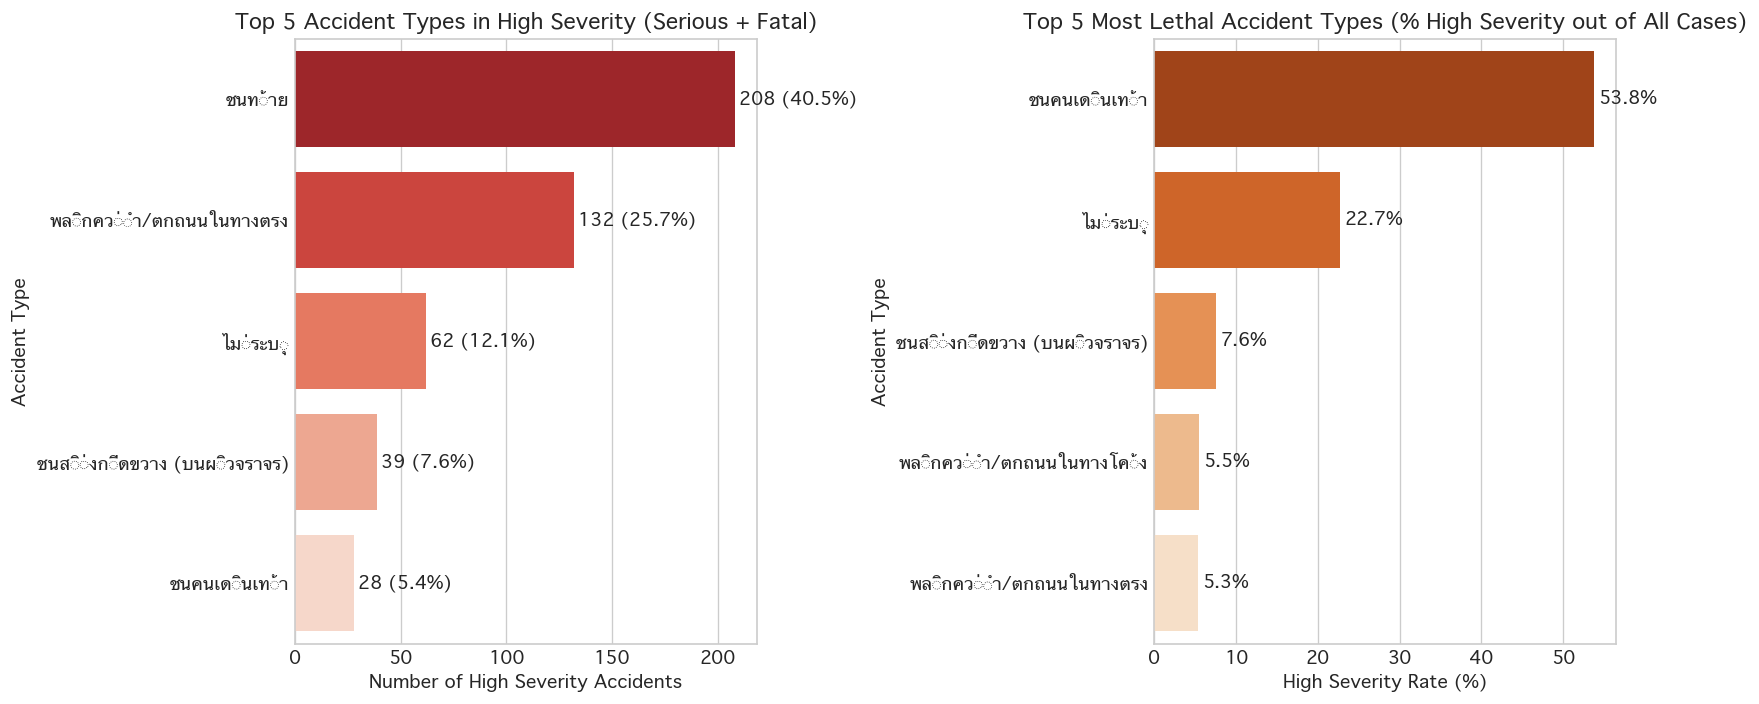

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: High Severity (Serious + Fatal)
top_5_types = high_sev_df['ลักษณะการเกิดเหตุ'].value_counts().head(5)
sns.barplot(x=top_5_types.values, y=top_5_types.index, palette='Reds_r', ax=axes[0])
axes[0].set_title('Top 5 Accident Types in High Severity (Serious + Fatal)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of High Severity Accidents')
axes[0].set_ylabel('Accident Type')

for i, v in enumerate(top_5_types.values):
    axes[0].text(v + 2, i, f"{v} ({v/len(high_sev_df)*100:.1f}%)", va='center', fontweight='bold')

# Plot 2: Lethality Rate by Accident Type
type_counts = df['ลักษณะการเกิดเหตุ'].value_counts()
high_counts = high_sev_df['ลักษณะการเกิดเหตุ'].value_counts()
lethality = (high_counts / type_counts * 100).dropna()
top_lethal = lethality[type_counts >= 50].sort_values(ascending=False).head(5)

sns.barplot(x=top_lethal.values, y=top_lethal.index, palette='Oranges_r', ax=axes[1])
axes[1].set_title('Top 5 Most Lethal Accident Types (% High Severity out of All Cases)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('High Severity Rate (%)')
axes[1].set_ylabel('Accident Type')

for i, v in enumerate(top_lethal.values):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Deep Dive: High Severity Drivers & Context

We analyze what vehicle types and temporal conditions drive these top high-severity accident types.


,รถและคนที่เกิดเหตุ,รถที่เกิดเหตุ,รถจักรยานยนต์,รถยนต์นั่งส่วนบุคคล,รถปิคอัพบรรทุก4ล้อ,รถบรรทุกมากกว่า10ล้อ
ลักษณะการเกิดเหตุ,,,,,,
ชนคนเดินเท้า,59,31,3,9,12,1
ชนท้าย,471,470,122,130,70,59
ชนสิ่งกีดขวาง (บนผิวจราจร),70,69,23,13,14,8
พลิกคว่ำ/ตกถนนในทางตรง,135,135,66,36,21,2
ไม่ระบุ,106,106,54,11,7,12


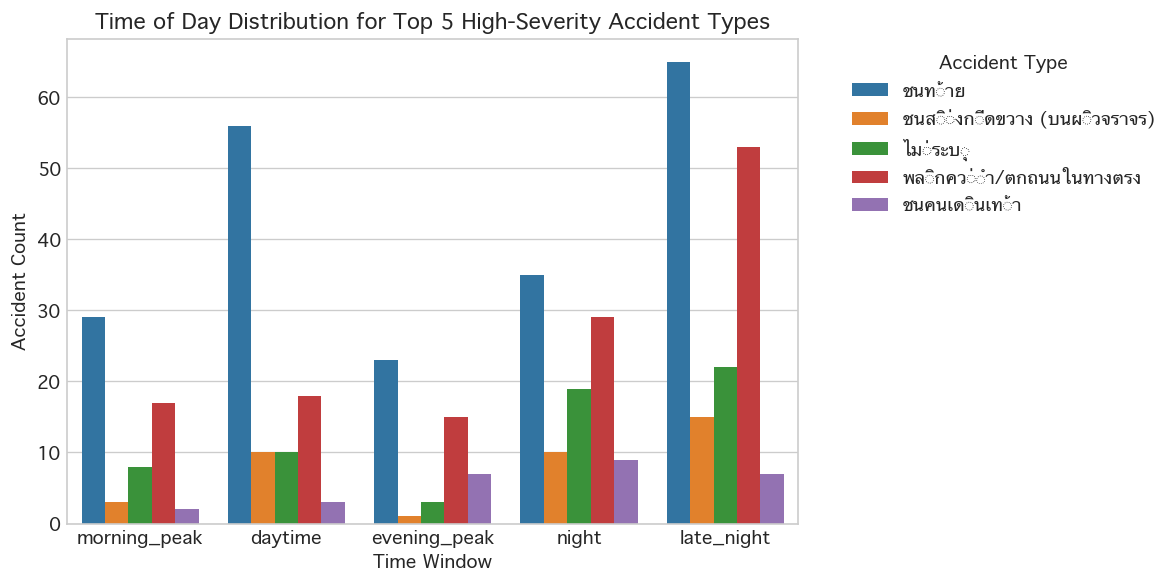

In [6]:
# Vehicle columns - ensure numeric conversion
veh_cols = [c for c in df.columns if c.startswith('รถ') or c == 'คนเดินเท้า']
for c in veh_cols:
    high_sev_df[c] = pd.to_numeric(high_sev_df[c], errors='coerce').fillna(0)

# Top 5 high severity accident types list
top_5_names = top_high['Accident Type (ลักษณะการเกิดเหตุ)'].tolist()
top_5_df = high_sev_df[high_sev_df['ลักษณะการเกิดเหตุ'].isin(top_5_names)]

# Vehicle involvement summary
veh_involvement = top_5_df.groupby('ลักษณะการเกิดเหตุ')[veh_cols].sum()
top_vehicles = veh_involvement.sum().sort_values(ascending=False).head(6).index
display(veh_involvement[top_vehicles])

# Plot Temporal Distribution (Time Bins) for Top High Severity Types
plt.figure(figsize=(10, 5))
sns.countplot(data=top_5_df, x='time_bin', hue='ลักษณะการเกิดเหตุ', palette='tab10',
              order=['morning_peak', 'daytime', 'evening_peak', 'night', 'late_night'])
plt.title('Time of Day Distribution for Top 5 High-Severity Accident Types', fontsize=13, fontweight='bold')
plt.xlabel('Time Window')
plt.ylabel('Accident Count')
plt.legend(title='Accident Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 5. Summary & Key Takeaways

### Top 5 Most Frequent High-Severity Accident Types (`severity >= 2`):
1. **ชนท้าย (Rear-end collision)**: **208 cases** (40.47% of high severity accidents) — The #1 cause of high-severity incidents, heavily occurring during night/late-night speed differentials and highway merges.
2. **พลิกคว่ำ/ตกถนนในทางตรง (Rollover / Off-road on straight section)**: **132 cases** (25.68%) — High speed, driver fatigue, or loss of control on straight stretches.
3. **ไม่ระบุ (Unspecified / Missing details)**: **62 cases** (12.06%).
4. **ชนสิ่งกีดขวาง (บนผิวจราจร) (Collision with obstacle on road surface)**: **39 cases** (7.59%) — Hitting barriers, signposts, or parked vehicles.
5. **ชนคนเดินเท้า (Pedestrian collision)**: **28 cases** (5.45%) — High lethality rate per collision.

*(Note: If excluding 'ไม่ระบุ', #5 becomes **พลิกคว่ำ/ตกถนนในทางโค้ง** with 14 cases).*

### High-Risk Insights:
- **Pedestrian collisions (`ชนคนเดินเท้า`)** have one of the highest high-severity ratios relative to total occurrences.
- **Rear-end (`ชนท้าย`) and Rollovers (`พลิกคว่ำ/ตกถนนในทางตรง`)** account for over **66% of all high-severity accidents** in Bangkok.
